# Planet Nine and the Secular Dynamics of Distant TNOs

*Matthew Payne*

About a dozen of the most distant known trans-Neptunian objects (TNOs), with semi-major axes beyond about 150 au and pericentres outside Neptune's orbit, appear to have their orbits clustered in orientation (Trujillo & Sheppard 2014). One proposed explanation is an undiscovered planet several times the Earth's mass on a wide, eccentric orbit: "Planet Nine" (Batygin & Brown 2016). How could such a planet herd the TNOs? Mean-motion resonances play a part, but much of the shaping is *secular*: the slow torque of Planet Nine's orbit, averaged over millions of orbits, acting on the TNOs' orbits.

This notebook reproduces, by direct numerical averaging, the secular analysis of

> G. Li, S. Hadden, M. Payne & M. J. Holman (2018), *The Secular Dynamics of TNOs and Planet Nine Interactions*, AJ **156**, 263. [ADS](https://ui.adsabs.harvard.edu/abs/2018AJ....156..263L/abstract) · [arXiv:1806.06867](https://arxiv.org/abs/1806.06867)

which we refer to as LHPH18.

We will:

1. Write down the averaged equations for a TNO perturbed by an eccentric Planet Nine and by the giant planets, and check them against analytic precession rates and a direct $N$-body integration.
2. Follow LHPH18's example TNO, whose pericentre stays anti-aligned with Planet Nine's.
3. Evolve an ensemble of TNOs started anti-aligned with Planet Nine for 4 billion years, and look for the clustering of their orbits.
4. Map which TNO orbits Planet Nine can flip over, with and without the giant planets.

Figure numbers in the text refer to the arXiv version of LHPH18.

**Requirements:** `numpy`, `scipy`, `matplotlib` and `rebound`.

**Run time:** the ensemble and the flip map took about 30 hours on a 12-core laptop (6 for the ensemble, 25 for the flip map) and are cached in `cache/`, so the notebook normally runs in a few minutes. Set `RECOMPUTE = True` to redo them, or `QUICK = True` for much smaller and shorter versions, which test the code in a few minutes but are too short to show the results.

In [1]:
import os
import time
from multiprocessing import Pool

import matplotlib.pyplot as plt
import numpy as np

import p9sec as ps    # helper module in this folder: the averaged equations

QUICK = False
RECOMPUTE = False
CACHE = "cache_quick" if QUICK else "cache"
NPROC = os.cpu_count()
os.makedirs(CACHE, exist_ok=True)
DEG = np.pi / 180
print(f"Using {NPROC} processes; QUICK = {QUICK}")

Using 12 processes; QUICK = False


## 1. The averaged equations

Planet Nine (mass $m_9$, semi-major axis $a_9$, eccentricity $e_9$) and the TNO both orbit the Sun. Over long times, what matters is the interaction averaged over both orbits; LHPH18 write the averaged interaction energy as

$$H_{\rm sec,0} = -\frac{G m_9}{4\pi^2}\int_0^{2\pi}\!\!\int_0^{2\pi}\left(\frac{1}{|\vec r - \vec r_9|} - \frac{\vec r\cdot\vec r_9}{r_9^3}\right) dl\,dl_9 ,$$

where $l$ and $l_9$ are the mean anomalies (their Eq. 1). Because the two orbits can have comparable sizes, this is not expanded in powers of $a/a_9$; it is evaluated numerically. The four giant planets are far inside the TNOs' orbits, so their averaged effect is that of a quadrupole, a $J_2$ term with $J_2R^2 = \tfrac12\sum m_p a_p^2/M_\odot$ (their Eq. 2). It also makes Planet Nine's orbit precess (their Eq. 3).

We evaluate the same averages in Gauss's form: the force on the TNO is averaged over Planet Nine's orbit at each point of the TNO's orbit, and the time-averaged rates of change of the TNO's eccentricity vector $\vec e$ and angular momentum $\vec h$,

$$\dot{\vec h} = \langle \vec r\times\vec F\rangle, \qquad \dot{\vec e} = \frac{1}{GM_\odot}\langle \vec F\times\vec h + \vec v\times(\vec r\times\vec F)\rangle ,$$

follow from Gauss's equations (`p9sec.Secular`). The semi-major axis is constant. Both orbits are sampled uniformly in eccentric anomaly, with weights $(1-e\cos E)$ that turn sums into time averages and resolve the pericentre of eccentric orbits. Where the two orbits pass within 15 au of each other, the integrand is sharply peaked; there the sampling is refined from 96 to 256 points per orbit, and a softening length of 2 au regularises the crossing itself. (At 256 points the averaged rates are accurate to about 3% at a near-crossing, and to better than $10^{-4}$ elsewhere.)

**Check 1: the giant planets alone.** With Planet Nine switched off, a TNO's orbit should precess at the classical $J_2$ rates, with $e$ and $i$ constant.

In [2]:
a, e, i = 300.0, 0.85, 10 * DEG
r = ps.evolve((a, e, i, 0.3, 0.2, 2.0e8, 50, dict(m9=0.0)))
dw, dO = ps.p9_precession(a, e)          # LHPH18 Eq. 3, which applies to any orbit at low inclination
ci = np.cos(i)
w_rate = (np.unwrap(r["w"])[-1] - r["w"][0]) / r["t"][-1]
O_rate = (np.unwrap(r["O"])[-1] - r["O"][0]) / r["t"][-1]
print(f"d(omega)/dt: averaged equations {w_rate / DEG * 1e9:9.3f} deg/Gyr, analytic {dw * (5 * ci**2 - 1) / 4 / DEG * 1e9:9.3f}")
print(f"d(Omega)/dt: averaged equations {O_rate / DEG * 1e9:9.3f} deg/Gyr, analytic {dO * ci / DEG * 1e9:9.3f}")
print(f"e stays within {r['e'].min():.8f} - {r['e'].max():.8f}")

d(omega)/dt: averaged equations  1656.164 deg/Gyr, analytic  1656.164
d(Omega)/dt: averaged equations  -847.443 deg/Gyr, analytic  -847.443
e stays within 0.85000000 - 0.85000000


(The analytic rates include the usual inclination factors, $(5\cos^2 i - 1)/4$ and $\cos i$, which LHPH18's low-inclination Eq. 3 omits.)

**Check 2: an $N$-body integration.** LHPH18's appendix compares direct averaging with REBOUND's IAS15 integrator for a star, Planet Nine and one TNO. We do the same for a TNO with $a = 150$ au, $e = 0.75$, $i = 10°$, anti-aligned with Planet Nine, over one billion years. (The $N$-body run takes several minutes, so it is cached.)

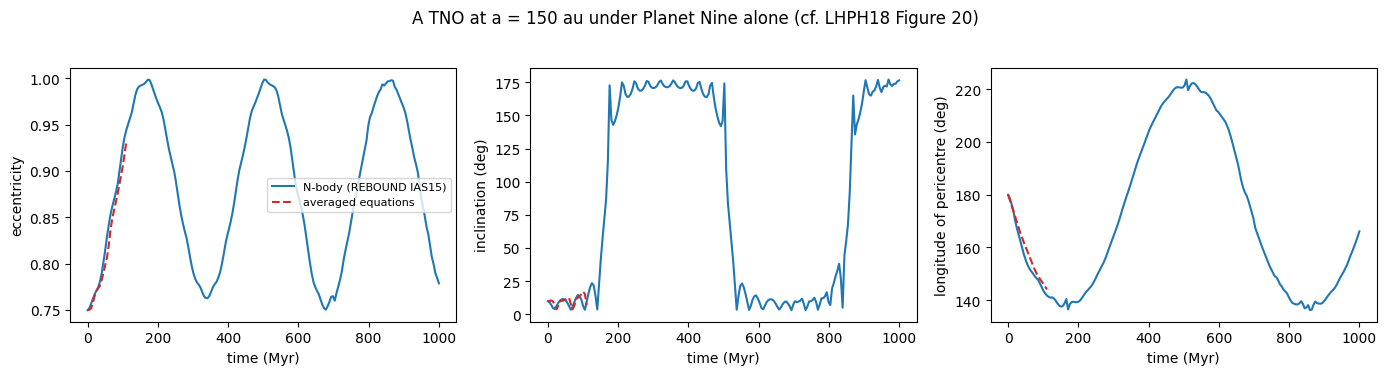

N-body semi-major axis stays within 149.7 - 158.4 au


In [3]:
path = os.path.join(CACHE, "nbody_check.npz")
T_CHECK, N_CHECK = 1.0e9, 200
a, e, i, w, O = 150.0, 0.75, 10 * DEG, np.pi, 0.0
sec = ps.evolve((a, e, i, w, O, T_CHECK, N_CHECK, dict(j2=False)))
if os.path.exists(path) and not RECOMPUTE:
    nb = dict(np.load(path))
else:
    import rebound
    sim = rebound.Simulation()
    sim.G = ps.G
    sim.add(m=1.0)
    sim.add(m=10 * ps.M_EARTH, a=500.0, e=0.6, inc=0.0, omega=0.0, Omega=0.0, M=0.3)
    sim.add(m=0.0, a=a, e=e, inc=i, omega=w, Omega=O, M=1.0)
    sim.N_active = 2
    sim.integrator = "ias15"
    sim.move_to_com()
    rows = []
    for t in np.linspace(0, T_CHECK, N_CHECK):
        sim.integrate(t)
        o = sim.particles[2].orbit(primary=sim.particles[0])
        rows.append((t, o.a, o.e, o.inc, o.pomega))
    rows = np.array(rows)
    nb = dict(t=rows[:, 0], a=rows[:, 1], e=rows[:, 2], i=rows[:, 3], varpi=rows[:, 4] % (2 * np.pi))
    np.savez(path, **nb)

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, key, lab, scale in zip(axs, ["e", "i", "varpi"], ["eccentricity", "inclination (deg)", "longitude of pericentre (deg)"], [1, 1 / DEG, 1 / DEG]):
    ax.plot(nb["t"] / 1e6, nb[key] * scale, color="C0", lw=1.5, label="N-body (REBOUND IAS15)")
    ax.plot(sec["t"] / 1e6, sec[key] * scale, "--", color="C3", lw=1.5, label="averaged equations")
    ax.set(xlabel="time (Myr)", ylabel=lab)
axs[0].legend(fontsize=8)
fig.suptitle("A TNO at a = 150 au under Planet Nine alone (cf. LHPH18 Figure 20)", y=1.03)
fig.tight_layout()
plt.show()
print(f"N-body semi-major axis stays within {nb['a'].min():.1f} - {nb['a'].max():.1f} au")

The averaged equations (dashed) follow the $N$-body integration (solid) closely: the eccentricity climbs from 0.75 towards 0.93, the longitude of pericentre drifts from 180° towards 145°, and the inclination stays near 10°. The dashed curves end after about 110 million years, when the pericentre falls below 10 au and our integration stops (Section 3 explains this rule). The semi-major axis in the $N$-body run stays between 150 and 158 au, close to constant, as the averaged equations assume.

The $N$-body run shows what happens next. With no giant planets in this test, the eccentricity keeps rising, to 0.998 (a pericentre of 0.2 au), and at that point the orbit flips: the inclination jumps from about 10° to about 170°, and back again 350 million years later. Planet Nine on its own flips this orbit, but only by first making it almost radial. This matters for the flip map in Section 4.

## 2. LHPH18's example TNO

LHPH18's Figure 2 follows a TNO with $a = 368.75$ au, $e = 0.867$ (pericentre 49 au), $i = 10°$ and its longitude of pericentre $\varpi$ anti-aligned with Planet Nine's, under their standard Planet Nine: $m_9 = 10\,M_\oplus$, $a_9 = 500$ au, $e_9 = 0.6$, in the plane of the giant planets. From here on, the giant planets' $J_2$ term is included.

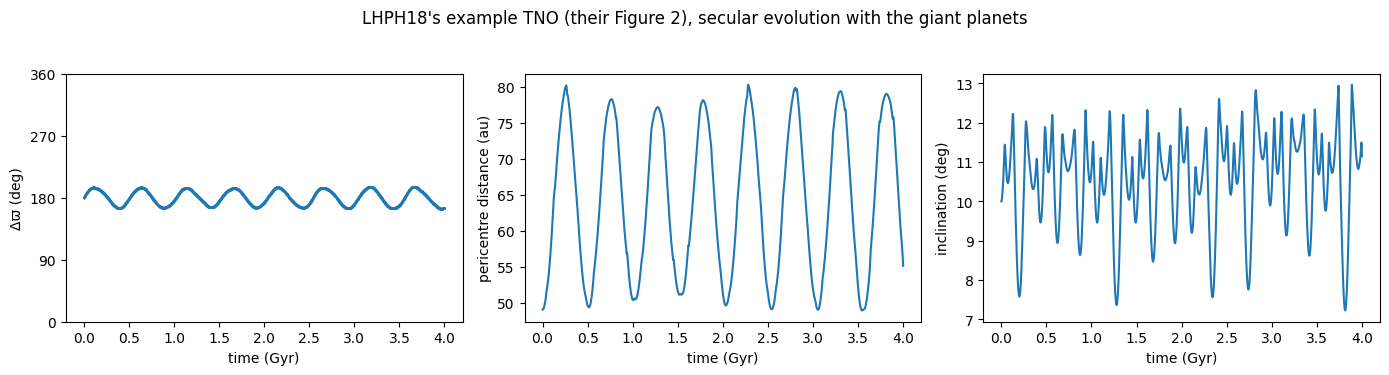

Δϖ stays between 164 and 196 deg; pericentre between 48.9 and 80.3 au; i up to 13.0 deg


In [4]:
ex1 = ps.evolve((368.75, 0.867, 10 * DEG, 0.0, np.pi, 4.0e9, 2000, {}))
dvarpi = ((ex1["varpi"] - ex1["varpi9"]) % (2 * np.pi)) / DEG
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
axs[0].plot(ex1["t"] / 1e9, dvarpi, ".", ms=1.5)
axs[0].set(xlabel="time (Gyr)", ylabel="Δϖ (deg)", ylim=(0, 360), yticks=[0, 90, 180, 270, 360])
axs[1].plot(ex1["t"] / 1e9, 368.75 * (1 - ex1["e"]))
axs[1].set(xlabel="time (Gyr)", ylabel="pericentre distance (au)")
axs[2].plot(ex1["t"] / 1e9, ex1["i"] / DEG)
axs[2].set(xlabel="time (Gyr)", ylabel="inclination (deg)")
fig.suptitle("LHPH18's example TNO (their Figure 2), secular evolution with the giant planets", y=1.03)
fig.tight_layout()
plt.show()
print(f"Δϖ stays between {dvarpi.min():.0f} and {dvarpi.max():.0f} deg; pericentre between "
      f"{368.75 * (1 - ex1['e']).min():.1f} and {368.75 * (1 - ex1['e']).max():.1f} au; i up to {ex1['i'].max() / DEG:.1f} deg")

As in LHPH18's Figure 2, the TNO's pericentre stays anti-aligned with Planet Nine's: $\Delta\varpi$ librates between 164° and 196°, about 180°, for the full 4 billion years, with a period of about half a billion years. Its pericentre distance oscillates between 49 and 80 au in step with $\Delta\varpi$, and its inclination stays between 7° and 13°. Orbits like this one, outside Neptune's reach and locked anti-aligned, are what the secular explanation of the clustering needs.

## 3. An ensemble of anti-aligned TNOs

LHPH18 (their Sec. 2.2) evolve 500 test particles with semi-major axes from 150 to 550 au, pericentre distances from 30 to 50 au, $i = 10°$, $\varpi = 180°$ (anti-aligned with Planet Nine's $\varpi_9 = 0$) and $\omega$ uniform, for 4 billion years. Particles whose orbits cross Planet Nine's are expensive with our refined sampling, so we evolve 250 of them, which is enough to see the patterns. (`QUICK` evolves 12 of them for 0.5 billion years, as a quick test of the code rather than a result.)

One departure from LHPH18: if a TNO's pericentre falls below 10 au, deep inside Neptune's orbit, we stop following it. In reality the giant planets would scatter it, which the secular model cannot describe (LHPH18 make the same point in their Sec. 2.2 but keep integrating), and as $e \to 1$ the averaged equations become very slow to integrate.

In [5]:
N_ENS = 12 if QUICK else 250
T_END, N_OUT = (5.0e8, 250) if QUICK else (4.0e9, 1000)
path = os.path.join(CACHE, f"ensemble_{N_ENS}.npz")
ic = ps.anti_aligned_ensemble(N_ENS)
if os.path.exists(path) and not RECOMPUTE:
    ens = dict(np.load(path))
else:
    t0 = time.time()
    jobs = [(ic["a"][k], ic["e"][k], ic["i"][k], ic["w"][k], ic["O"][k], T_END, N_OUT) for k in range(N_ENS)]
    order = np.argsort(-ic["a"])          # the widest (slowest) orbits first, to keep the pool busy
    with Pool(NPROC) as pool:
        res = pool.map(ps.ensemble_member, [jobs[k] for k in order], chunksize=1)
    res = [res[list(order).index(k)] for k in range(N_ENS)]
    ens = {key: np.array([r[key] for r in res]) for key in res[0]}
    ens.update(a=ic["a"], t=np.linspace(0, T_END, N_OUT))
    np.savez_compressed(path, **ens)
    print(f"({time.time() - t0:.0f} s)")
ens["rp"] = ens["a"][:, None] * (1 - ens["e"])
flipped = (ens["i"] > np.pi / 2).any(axis=1)
stopped = ens["t_stop"] < T_END
print(f"{flipped.sum()} of {N_ENS} TNOs ({flipped.mean():.0%}) flipped past 90° within {T_END / 1e9:g} Gyr (LHPH18: 105 of 500 in 4 Gyr, 21%)")
print(f"{stopped.sum()} of {N_ENS} were stopped when their pericentre fell below {ps.RP_STOP:.0f} au "
      f"({np.sum(stopped & flipped)} of them after flipping)")

/Users/matthewjohnpayne/git_repos/science-notebooks/notebooks/planet_nine/p9sec.py:55: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(1 - e * e)


/Users/matthewjohnpayne/git_repos/science-notebooks/notebooks/planet_nine/p9sec.py:55: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(1 - e * e)


/Users/matthewjohnpayne/git_repos/science-notebooks/notebooks/planet_nine/p9sec.py:55: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(1 - e * e)


(22868 s)
34 of 250 TNOs (14%) flipped past 90° within 4 Gyr (LHPH18: 105 of 500, 21%)
23 of 250 were stopped when their pericentre fell below 10 au (12 of them after flipping)


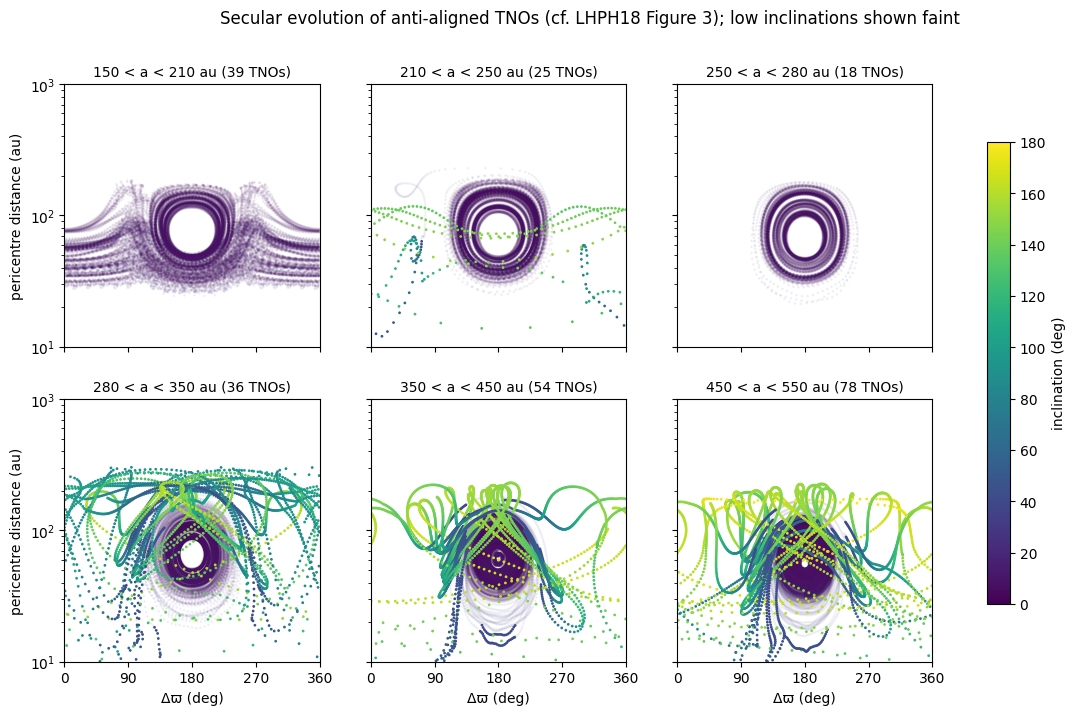

In [6]:
a_bins = [(150, 210), (210, 250), (250, 280), (280, 350), (350, 450), (450, 550)]
fig, axs = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True, sharey=True)
for ax, (lo, hi) in zip(axs.ravel(), a_bins):
    sel = (ens["a"] >= lo) & (ens["a"] < hi)
    x = ens["dvarpi"][sel].ravel() / DEG
    y = ens["rp"][sel].ravel()
    c = ens["i"][sel].ravel() / DEG
    low = c < 40
    ax.scatter(x[low], y[low], c=c[low], s=1, cmap="viridis", vmin=0, vmax=180, alpha=0.05, rasterized=True)
    sc = ax.scatter(x[~low], y[~low], c=c[~low], s=1, cmap="viridis", vmin=0, vmax=180, rasterized=True)
    ax.set_title(f"{lo} < a < {hi} au ({sel.sum()} TNOs)", fontsize=10)
    ax.set(yscale="log", ylim=(10, 1000), xlim=(0, 360), xticks=[0, 90, 180, 270, 360])
for ax in axs[-1]:
    ax.set_xlabel("Δϖ (deg)")
for ax in axs[:, 0]:
    ax.set_ylabel("pericentre distance (au)")
fig.colorbar(sc, ax=axs, label="inclination (deg)", shrink=0.8)
fig.suptitle("Secular evolution of anti-aligned TNOs (cf. LHPH18 Figure 3); low inclinations shown faint", y=0.98)
plt.show()

Each panel shows the paths of the TNOs in one range of semi-major axis, in the plane of $\Delta\varpi$ and pericentre distance, coloured by inclination; low-inclination paths are faint so that the flipped orbits stand out. Three regimes appear, as in LHPH18's Figure 3:

* **150–210 au.** The giant planets' $J_2$ term dominates. Most TNOs circulate: only 15 of 39 keep $\Delta\varpi$ between 90° and 270° throughout. None flips.
* **210–280 au.** Planet Nine's torque wins, and all 42 TNOs that stay at low inclination librate about $\Delta\varpi = 180°$, tracing closed loops in which the pericentre rises and falls by tens of au. One flips.
* **280–550 au.** Most TNOs still librate, but Planet Nine also drives large changes in inclination: 33 of 168 flip past 90° (yellow and green paths), and 23 are stopped when their pericentre falls below 10 au.

Over the whole ensemble, 34 of 250 TNOs (14%) flip within 4 Gyr, against 105 of 500 (21%) in LHPH18. Part of the difference is our stopping rule: 12 of the 34 flipped TNOs were stopped afterwards, and some that were stopped before flipping might have flipped later.

Observed distant TNOs have pericentres below about 80 au and have survived for billions of years. LHPH18 therefore look at snapshots after 3 Gyr with $30 < r_p < 80$ au, and measure the orientation with the *geometrical longitude of pericentre* $\theta_e$, the direction of the pericentre projected onto the plane of the planets (for low inclinations, $\theta_e \approx \varpi$).

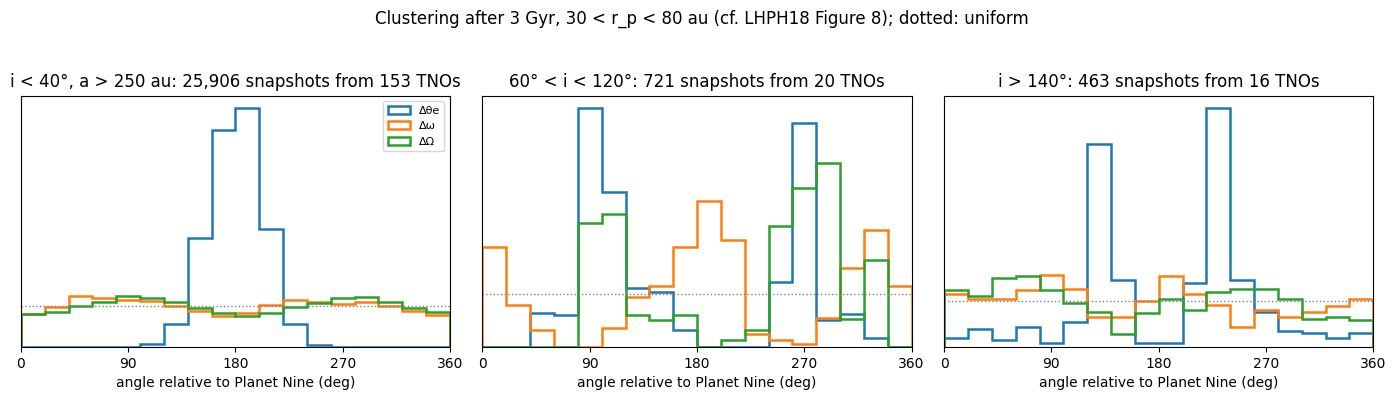

Low-inclination snapshots with |Δθe - 180°| < 45°: 95% (25% if uniform)


In [7]:
late = ens["t"] > 0.75 * ens["t"][-1]    # after 3 Gyr (QUICK: after 0.375 Gyr)
vis = (ens["rp"] > 30) & (ens["rp"] < 80) & late[None, :]
inc = ens["i"] / DEG
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (lo, hi, lab, amin) in zip(axs, [(0, 40, "i < 40°, a > 250 au", 250), (60, 120, "60° < i < 120°", 0), (140, 180, "i > 140°", 0)]):
    sel = vis & (inc >= lo) & (inc < hi) & (ens["a"][:, None] > amin)
    for key, col, name in [("dtheta", "C0", "Δθe"), ("dw", "C1", "Δω"), ("dO", "C2", "ΔΩ")]:
        ax.hist(ens[key][sel] / DEG, bins=np.linspace(0, 360, 19), histtype="step", lw=1.8, color=col, density=True, label=name)
    ax.axhline(1 / 360, color="0.5", ls=":", lw=1)
    ax.set(xlabel="angle relative to Planet Nine (deg)", xticks=[0, 90, 180, 270, 360], yticks=[],
           title=f"{lab}: {sel.sum():,} snapshots from {np.any(sel, axis=1).sum()} TNOs", xlim=(0, 360))
axs[0].legend(fontsize=8)
fig.suptitle("Clustering after 3 Gyr, 30 < r_p < 80 au (cf. LHPH18 Figure 8); dotted: uniform", y=1.04)
fig.tight_layout()
plt.show()

sel = vis & (inc < 40) & (ens["a"][:, None] > 250)
dth = ens["dtheta"][sel] / DEG
print(f"Low-inclination snapshots with |Δθe - 180°| < 45°: {np.mean(np.abs(dth - 180) < 45):.0%} (25% if uniform)")

Among the low-inclination TNOs beyond 250 au (left), $\theta_e$ is strongly clustered: 95% of the snapshots lie within 45° of anti-alignment with Planet Nine, against 25% if the orientations were random. The argument of pericentre $\omega$ and the node $\Omega$ are each close to uniform; only their sum, the pericentre direction, is confined. This is LHPH18's result: when $30 \lesssim r_p \lesssim 80$ au and $a \gtrsim 250$ au, the giant planets suppress the flips while the longitude of pericentre keeps librating, which aligns the pericentres of the low-inclination TNOs.

The high-inclination TNOs (middle and right) are a few objects each, so their histograms are noisy, but they are not uniform either: $\theta_e$ avoids alignment with Planet Nine, with peaks near 90° and 270° for $60° < i < 120°$ and on either side of 180° for $i > 140°$. Surveys of high-inclination distant TNOs could therefore test the model, as LHPH18 suggest.

## 4. Which orbits flip?

LHPH18's Figure 13 maps where an anti-aligned TNO's orbit can be flipped past 90° within 4 Gyr, as a function of its semi-major axis and pericentre, starting at $i = 5°$ with $\omega = 180°$ and $\Omega = 0$, with and without the giant planets. We recompute it on a grid.

/Users/matthewjohnpayne/git_repos/science-notebooks/notebooks/planet_nine/p9sec.py:55: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(1 - e * e)


/Users/matthewjohnpayne/git_repos/science-notebooks/notebooks/planet_nine/p9sec.py:55: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(1 - e * e)


/Users/matthewjohnpayne/git_repos/science-notebooks/notebooks/planet_nine/p9sec.py:55: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(1 - e * e)


/Users/matthewjohnpayne/git_repos/science-notebooks/notebooks/planet_nine/p9sec.py:55: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(1 - e * e)


/Users/matthewjohnpayne/git_repos/science-notebooks/notebooks/planet_nine/p9sec.py:55: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(1 - e * e)


/Users/matthewjohnpayne/git_repos/science-notebooks/notebooks/planet_nine/p9sec.py:55: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(1 - e * e)


/Users/matthewjohnpayne/git_repos/science-notebooks/notebooks/planet_nine/p9sec.py:55: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(1 - e * e)


/Users/matthewjohnpayne/git_repos/science-notebooks/notebooks/planet_nine/p9sec.py:55: RuntimeWarning: invalid value encountered in sqrt
  b = np.sqrt(1 - e * e)


(89174 s)


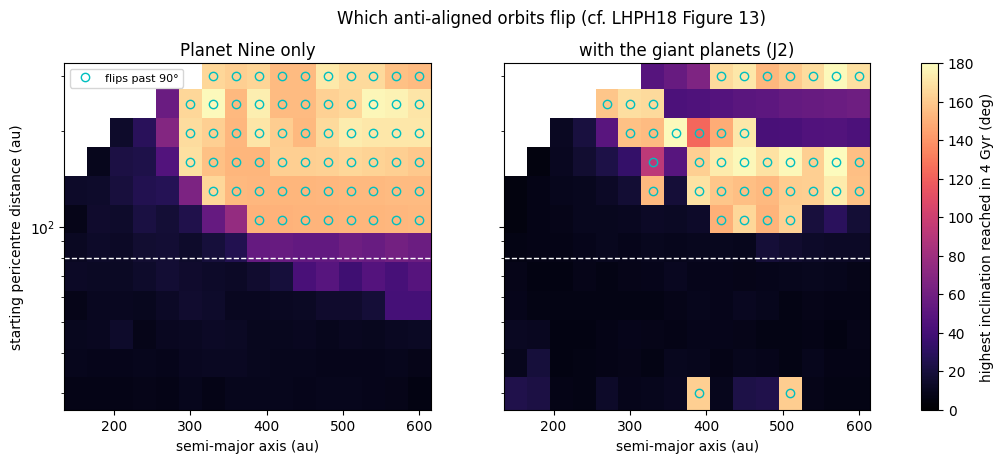

noj2: 61 of 179 grid points flip; with r_p < 80 au: 0 of 80
j2: 40 of 179 grid points flip; with r_p < 80 au: 2 of 80


In [8]:
A_GRID = np.arange(150, 601, 150 if QUICK else 30)
RP_GRID = np.round(np.geomspace(30, 300, 3 if QUICK else 12), 1)
T_FLIP = 2.5e8 if QUICK else 4.0e9
path = os.path.join(CACHE, f"flipmap_{len(A_GRID)}x{len(RP_GRID)}.npz")
if os.path.exists(path) and not RECOMPUTE:
    fm = dict(np.load(path))
else:
    t0 = time.time()
    jobs = [(a, rp, j2, T_FLIP) for j2 in (True, False) for a in A_GRID for rp in RP_GRID if rp < 0.95 * a]
    with Pool(NPROC) as pool:
        res = pool.map(ps.flip_run, jobs[::-1], chunksize=1)[::-1]
    fm = {f"flip_{tag}": np.full((len(A_GRID), len(RP_GRID)), -1, int) for tag in ("j2", "noj2")}
    fm.update({f"imax_{tag}": np.full((len(A_GRID), len(RP_GRID)), np.nan) for tag in ("j2", "noj2")})
    for (a, rp, j2, _), (flip, imax) in zip(jobs, res):
        ia, ir = list(A_GRID).index(a), list(RP_GRID).index(rp)
        tag = "j2" if j2 else "noj2"
        fm[f"flip_{tag}"][ia, ir], fm[f"imax_{tag}"][ia, ir] = int(flip), imax
    fm.update(a=A_GRID, rp=RP_GRID)
    np.savez(path, **fm)
    print(f"({time.time() - t0:.0f} s)")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, tag, title in zip(axs, ["noj2", "j2"], ["Planet Nine only", "with the giant planets (J2)"]):
    im = ax.pcolormesh(fm["a"], fm["rp"], np.ma.masked_less(fm[f"imax_{tag}"].T, 0), cmap="magma", vmin=0, vmax=180, shading="nearest")
    flip = fm[f"flip_{tag}"].T == 1
    A, R = np.meshgrid(fm["a"], fm["rp"])
    ax.plot(A[flip], R[flip], "o", mfc="none", mec="c", ms=6, label="flips past 90°")
    ax.axhline(80, color="w", ls="--", lw=1)
    ax.set(yscale="log", xlabel="semi-major axis (au)", title=title)
axs[0].set_ylabel("starting pericentre distance (au)")
axs[0].legend(loc="upper left", fontsize=8)
fig.colorbar(im, ax=axs, label="highest inclination reached in 4 Gyr (deg)")
fig.suptitle("Which anti-aligned orbits flip (cf. LHPH18 Figure 13)", y=1.0)
plt.show()
for tag in ("noj2", "j2"):
    f = fm[f"flip_{tag}"]
    print(f"{tag}: {np.sum(f == 1)} of {np.sum(f >= 0)} grid points flip; with r_p < 80 au: "
          f"{np.sum((f == 1) & (fm['rp'][None, :] < 80))} of {np.sum((f >= 0) & (fm['rp'][None, :] < 80))}")

Each cell is one TNO, coloured by the highest inclination it reaches in 4 Gyr; circles mark flips past 90°, and the dashed line is $r_p = 80$ au, roughly the largest pericentre among the observed clustered TNOs.

* **Planet Nine only (left).** Orbits with starting pericentres above about 100 au and semi-major axes above about 300 au flip (61 of 179 cells). Below 80 au none does in our map, but this is partly our stopping rule: as the $N$-body check in Section 1 shows, Planet Nine alone flips such orbits only after driving their pericentres far inside 10 au, and our integration stops before that.
* **With the giant planets (right).** The flipping region shrinks to 40 cells, and below 80 au the inclination stays under 25° everywhere except two isolated cells at $r_p = 30$ au ($a = 390$ and 510 au). With one trajectory per cell, we cannot tell whether those two are part of a small flipping region or individual orbits that happen to flip; we have not investigated them further. The $J_2$ precession breaks up the flipping region above 100 au too, leaving bands at pericentres of 200–250 au where many orbits reach only 40–60°.

So with the giant planets included, the TNOs in the observed range of pericentres keep low inclinations and anti-aligned pericentres, while flipped orbits come mainly from larger pericentres, in line with LHPH18.

## Summary

* Direct averaging of the Planet Nine interaction in Gauss's form reproduces the analytic $J_2$ precession rates exactly and follows an $N$-body integration closely until the TNO's pericentre falls below 10 au.
* LHPH18's example TNO keeps its pericentre anti-aligned with Planet Nine's for 4 Gyr, librating by $\pm16°$ while its pericentre moves between 49 and 80 au.
* In an ensemble of 250 anti-aligned TNOs, those beyond about 210 au librate about anti-alignment; closer in, the giant planets' precession makes most of them circulate. Beyond 280 au, about one in five flips.
* After 3 Gyr, 95% of the snapshots of low-inclination TNOs beyond 250 au with $30 < r_p < 80$ au are within 45° of anti-alignment, the clustering a secular Planet Nine produces.
* The giant planets suppress flips for TNOs with pericentres below 80 au; flips come mainly from orbits with larger pericentres. Planet Nine alone can still flip low-pericentre orbits, but only by first making them nearly radial.

## Going further

* **Other Planet Nines.** LHPH18's Figures 17 and 19 show how the libration region and the fraction of flipped orbits depend on Planet Nine's orbit: flips need an eccentric ($e_9 \gtrsim 0.4$), wide ($a_9 \approx 400$–800 au) planet of about 10 Earth masses. Change `a9`, `e9` and `m9` in `p9sec.Secular` and remake the flip map.
* **Resonances and scattering.** The secular model leaves out mean-motion resonances with Planet Nine and scattering by Neptune. LHPH18's Section 3 compares with $N$-body integrations including Neptune, and Hadden et al. (2018) map the chaotic, resonance-overlap region.
* **Randomly oriented TNOs.** Starting with $\varpi$ uniform rather than anti-aligned produces a second, aligned cluster in the secular dynamics, which $N$-body integrations show is unstable (LHPH18; Hadden et al. 2018).

## References

* Batygin, K. & Brown, M. E. 2016, *Evidence for a Distant Giant Planet in the Solar System*, AJ 151, 22. [ADS](https://ui.adsabs.harvard.edu/abs/2016AJ....151...22B/abstract)
* Batygin, K. & Morbidelli, A. 2017, *Dynamical Evolution Induced by Planet Nine*, AJ 154, 229. [ADS](https://ui.adsabs.harvard.edu/abs/2017AJ....154..229B/abstract)
* Beust, H. 2016, *Orbital clustering of distant Kuiper belt objects by hypothetical Planet 9. Secular or resonant?*, A&A 590, L2. [ADS](https://ui.adsabs.harvard.edu/abs/2016A&A...590L...2B/abstract)
* Hadden, S., Li, G., Payne, M. J. & Holman, M. J. 2018, *Chaotic Dynamics of Trans-Neptunian Objects Perturbed by Planet Nine*, AJ 155, 249. [ADS](https://ui.adsabs.harvard.edu/abs/2018AJ....155..249H/abstract)
* Li, G., Hadden, S., Payne, M. & Holman, M. J. 2018, *The Secular Dynamics of TNOs and Planet Nine Interactions*, AJ 156, 263. [ADS](https://ui.adsabs.harvard.edu/abs/2018AJ....156..263L/abstract)
* Rein, H. & Spiegel, D. S. 2015, *IAS15: a fast, adaptive, high-order integrator for gravitational dynamics, accurate to machine precision over a billion orbits*, MNRAS 446, 1424. [ADS](https://ui.adsabs.harvard.edu/abs/2015MNRAS.446.1424R/abstract)
* Trujillo, C. A. & Sheppard, S. S. 2014, *A Sedna-like body with a perihelion of 80 astronomical units*, Nature 507, 471. [ADS](https://ui.adsabs.harvard.edu/abs/2014Natur.507..471T/abstract)